# Model Training and Evaluation

---

1. Import packages
2. Load data
3. Modelling

---

## Import packages

In [36]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---
## Load data

In [38]:
df = pd.read_csv('C:/Users/hp/BCG X customer_churn_project/data/data_for_predictions.csv')
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_sales_MISSING,channel_sales_ewpakwlliwisiwduibdlfmalxowmwpci,channel_sales_foosdfpfkusacimwkcsosbicdxkicaua,channel_sales_lmkebamcaaclubfxadlmueccxoimlema,channel_sales_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.047073,0.040659,1.619163,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.059075,0.000000,1.656207,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.066622,0.036589,1.656207,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.059448,0.000000,1.656207,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.048014,0.041399,1.619163,...,71,9,1,0,0,0,0,1,0,0


---

## Modelling

We now have a dataset containing features that we have engineered and we are ready to start training a predictive model. I'm going to focus on training a `Random Forest` classifier.

In [39]:
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

### Data sampling

The first thing we want to do is split our dataset into training and test samples. The reason why we do this, is so that we can simulate a real life situation by generating predictions for our test sample, without showing the predictive model these data points. This gives us the ability to see how well our model is able to generalise to new data, which is critical.

A typical % to dedicate to testing is between 20-30, for this project we will use a 75-25% split between train and test respectively.

In [54]:
# Make a copy of our data
train_df = df.copy()

# Separate target variable from independent variables
y = df['churn']
X = df.drop(columns=['id', 'churn'])
print(X.shape)
print(y.shape)

(14606, 43)
(14606,)


In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(10954, 43)
(10954,)
(3652, 43)
(3652,)


### Model training

Once again, we are using a `Random Forest` classifier in this project. A Random Forest sits within the category of `ensemble` algorithms because internally the `Forest` refers to a collection of `Decision Trees` which are tree-based learning algorithms. As a data scientist, you can control how large the forest is (that is, how many decision trees you want to include).

The reason why an `ensemble` algorithm is powerful is because of the laws of averaging, weak learners and the central limit theorem. If we take a single decision tree and give it a sample of data and some parameters, it will learn patterns from the data. It may be overfit or it may be underfit, but that is now our only hope, that single algorithm. 

With `ensemble` methods, instead of banking on 1 single trained model, we can train 100's of decision trees, all using different splits of the data and learning different patterns. It would be like asking 100 people to all learn how to code. You would end up with 100 people with different answers, methods and styles! The weak learner notion applies here too, it has been found that if you train your learners not to overfit, but to learn weak patterns within the data and you have a lot of these weak learners, together they come together to form a highly predictive pool of knowledge! This is a real life application of many brains are better than 1.

Now instead of relying on 1 single decision tree for prediction, the random forest puts it to the overall views of the entire collection of decision trees. Some ensemble algorithms using a voting approach to decide which prediction is best, others using averaging. 

As we increase the number of learners, the idea is that the random forest's performance should converge to its best possible solution.

Some additional advantages of the random forest classifier include:

- The random forest uses a rule-based approach instead of a distance calculation and so features do not need to be scaled
- It is able to handle non-linear parameters better than linear based models

On the flip side, some disadvantages of the random forest classifier include:

- The computational power needed to train a random forest on a large dataset is high, since we need to build a whole ensemble of estimators.
- Training time can be longer due to the increased complexity and size of the ensemble

In [42]:
model = RandomForestClassifier(
    n_estimators=100
)
model.fit(X_train, y_train)

RandomForestClassifier()

For this project, I am using `n_estimators` = 100. This means that my random forest will consist of 100 decision trees. There are many more parameters that you can fine-tune within the random forest and finding the optimal combinations of parameters can be a manual task of exploration, trial and error, which will not be covered during this notebook.

### Evaluation

Now let's evaluate how well this trained model is able to predict the values of the test dataset.

We are going to use 3 metrics to evaluate performance:

- Accuracy = the ratio of correctly predicted observations to the total observations
- Precision = the ability of the classifier to not label a negative sample as positive
- Recall = the ability of the classifier to find all the positive samples

The reason why we are using these three metrics is because a simple accuracy is not always a good measure to use. To give an example, let's say you're predicting heart failures with patients in a hospital and there were 100 patients out of 1000 that did have a heart failure. 

If you predicted 80 out of 100 (80%) of the patients that did have a heart failure correctly, you might think that you've done well! However, this also means that you predicted 20 wrong and what may the implications of predicting these remaining 20 patients wrong? Maybe they miss out on getting vital treatment to save their lives. 

As well as this, what about the impact of predicting negative cases as positive (people not having heart failure being predicted that they did), maybe a high number of false positives means that resources get used up on the wrong people and a lot of time is wasted when they could have been helping the real heart failure sufferers. 

This is just an example, but it illustrates why other performance metrics are necessary such `Precision` and `Recall`, which are good measures to use in a classification scenario.

In [43]:
predictions = model.predict(X_test)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, predictions).ravel()

In [44]:
y_test.value_counts()

churn
0    3286
1     366
Name: count, dtype: int64

In [45]:
print(f"True positives: {tp}")
print(f"False positives: {fp}")
print(f"True negatives: {tn}")
print(f"False negatives: {fn}\n")

print(f"Accuracy: {metrics.accuracy_score(y_test, predictions)}")
print(f"Precision: {metrics.precision_score(y_test, predictions)}")
print(f"Recall: {metrics.recall_score(y_test, predictions)}")

True positives: 19
False positives: 3
True negatives: 3283
False negatives: 347

Accuracy: 0.9041621029572837
Precision: 0.8636363636363636
Recall: 0.05191256830601093


Looking at these results there are a few things to point out:

- Within the test set about 10% of the rows are churners (churn = 1).
- Looking at the True negatives, we have 3283 out of 3286. This means that out of all the negative cases (churn = 0), we predicted 3283 as negative (hence the name True negative). This is great!
- Looking at the False negatives, this is where we have predicted a client to not churn (churn = 0) when in fact they did churn (churn = 1). This number is quite high at 347, we want to get the False negatives to as close to 0 as we can, so this would need to be addressed when improving the model.
- Looking at False positives, this is where we have predicted a client to churn when they actually didn't churn. For this value we can see there is 3 case, which is great!
- With the True positives, we can see that in total we have 366 clients that churned in the test dataset. However, we are only able to correctly identify 19 of those 366, which is very poor.
- Looking at the accuracy score, this is very misleading! Hence the use of precision and recall is important. The accuracy score is high, but it does not tell us the whole story.
- Looking at the precision score, this shows us a score of 0.86 which is good.
- However, the recall shows us that the classifier has a very poor ability to identify positive samples. This would be the main concern for improving this model!

So overall, we're able to very accurately identify clients that do not churn, but we are not able to predict cases where clients do churn! What we are seeing is that a high % of clients are being identified as not churning when they should be identified as churning. This in turn tells us that the current set of features are not discriminative enough to clearly distinguish between churners and non-churners. 

A data scientist at this point would go back to feature engineering to try and create more predictive features. They may also experiment with optimising the parameters within the model to improve performance. For now, lets dive into understanding the model a little more.

### Model understanding

A simple way of understanding the results of a model is to look at feature importances. Feature importances indicate the importance of a feature within the predictive model, there are several ways to calculate feature importance, but with the Random Forest classifier, we're able to extract feature importances using the built-in method on the trained model. In the Random Forest case, the feature importance represents the number of times each feature is used for splitting across all trees.

In [46]:
feature_importances = pd.DataFrame({
    'features': X_train.columns,
    'importance': model.feature_importances_
}).sort_values(by='importance', ascending=True).reset_index()


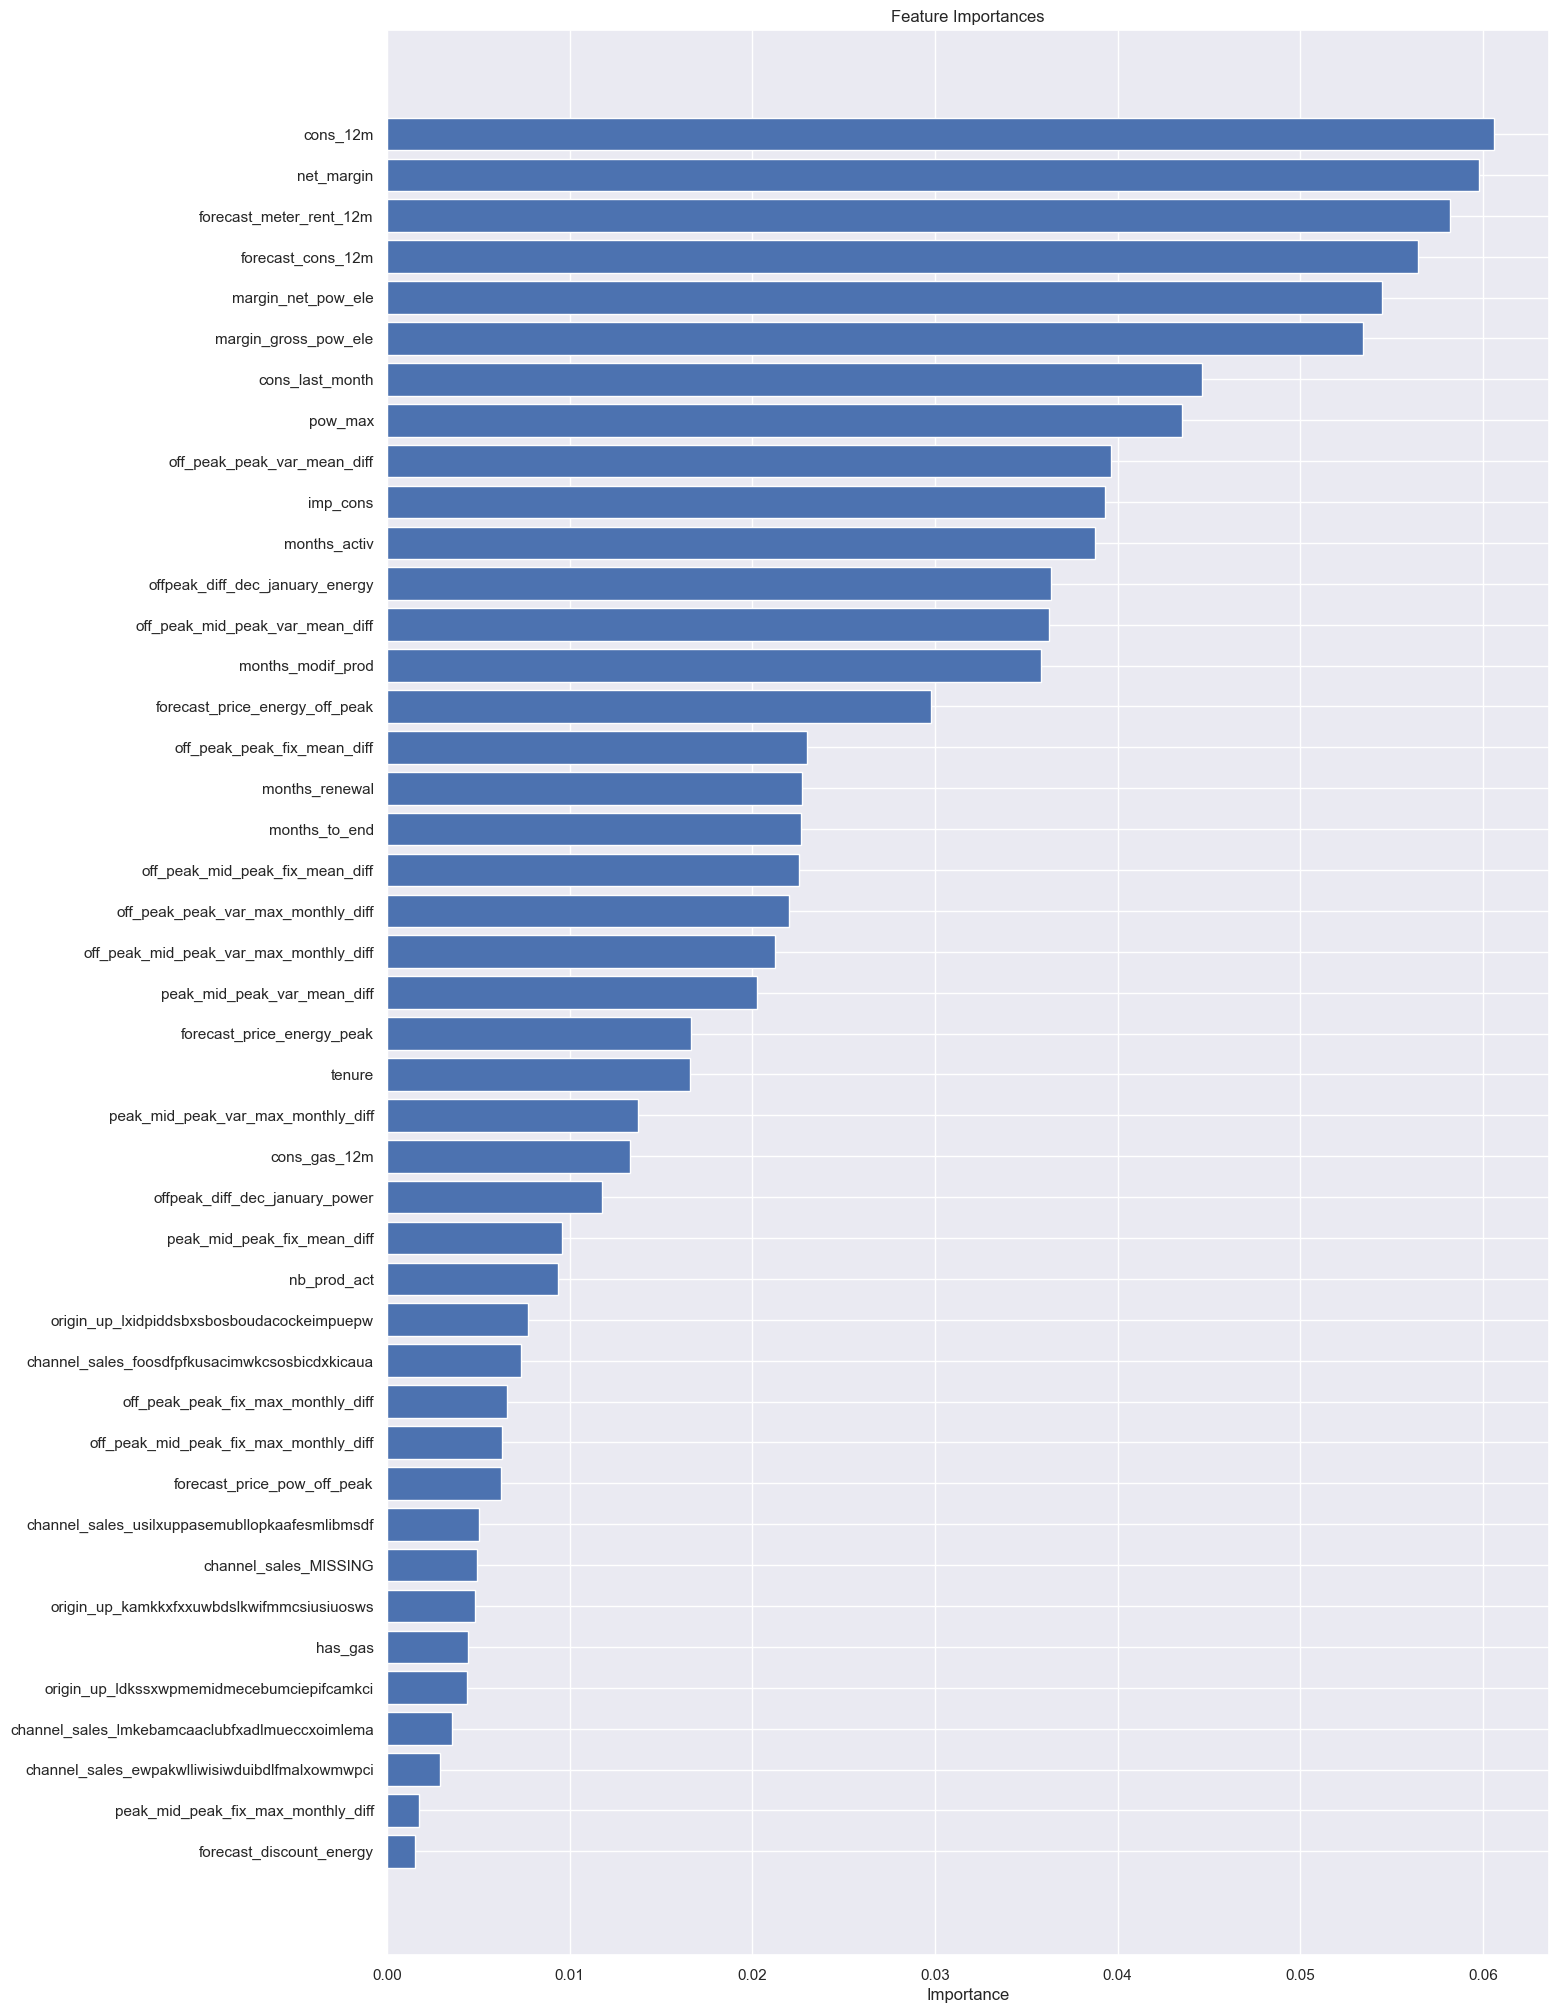

In [47]:
plt.figure(figsize=(15, 25))
plt.title('Feature Importances')
plt.barh(range(len(feature_importances)), feature_importances['importance'], color='b', align='center')
plt.yticks(range(len(feature_importances)), feature_importances['features'])
plt.xlabel('Importance')
plt.show()

From this chart, we can observe the following points:

- Consumption over 12 months and Net margin is a top driver for churn in this model
- Margin on power subscription also is an influential driver
- Time seems to be an influential factor, especially the number of months they have been active, their tenure and the number of months since they updated their contract
- Our price sensitivity features are scattered around but are not the main driver for a customer churning

The last observation is important because this relates back to our original hypothesis:

    > Is churn driven by the customers' price sensitivity?

Based on the output of the feature importances, it is not a main driver but it is a weak contributor. However, to arrive at a conclusive result, more experimentation is needed.

In [48]:
proba_predictions = model.predict_proba(X_test)
probabilities = proba_predictions[:, 1]

In [49]:
X_test = X_test.reset_index()
X_test.drop(columns='index', inplace=True)

In [50]:
X_test['churn'] = predictions.tolist()
X_test['churn_probability'] = probabilities.tolist()
X_test.to_csv('out_of_sample_data_with_predictions.csv')

## Save the Model for Building FastApi app

In [51]:
# Save model, feature names and metrics to disk
import joblib
import os

# Create model folder
os.makedirs('C:/Users/hp/BCG X customer_churn_project/model', exist_ok=True)

# Save the trained model
joblib.dump(model, 'C:/Users/hp/BCG X customer_churn_project/model/churn_model.pkl')
# serializes the entire Random Forest (all 1000 trees) to a binary file
# .pkl = pickle format — preserves the model's state exactly as trained

# save feature names
feature_names = X_train.columns.tolist()

# save the feature names list so the API can reindex incoming data correctly
joblib.dump(feature_names, 'C:/Users/hp/BCG X customer_churn_project/model/feature_names.pkl')


['C:/Users/hp/BCG X customer_churn_project/model/feature_names.pkl']

In [52]:
# Save model metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# recalculate metrics using the predictions already generated
accuracy  = accuracy_score(y_test, predictions) 
precision = precision_score(y_test, predictions) 
recall    = recall_score(y_test, predictions)

# extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
# tn: correctly predicted no-churn
# fp: wrongly predicted as churn
# fn: missed actual churners (most costly error)
# tp: correctly predicted churners

# store all metrics in a dictionary for the API to display
model_metrics = {
    'accuracy':               round(float(accuracy),  4),
    'precision':              round(float(precision), 4),
    'recall':                 round(float(recall),    4),
    'tp':                     int(tp), 
    'fp':                     int(fp),  
    'tn':                     int(tn), 
    'fn':                     int(fn), 
    'total_churners_in_test': int(tp+fn), 
    'churners_caught':        int(tp),    
}

# save metrics so the API can display them without recalculating every time
joblib.dump(model_metrics, 'C:/Users/hp/BCG X customer_churn_project/model/model_metrics.pkl')

['C:/Users/hp/BCG X customer_churn_project/model/model_metrics.pkl']

In [53]:
# Confirmation
print("Model saved to:   model/churn_model.pkl")
print(f"   File size: {os.path.getsize('C:/Users/hp/BCG X customer_churn_project/model/churn_model.pkl') / (1024*1024):.1f} MB")
print(f"\n Feature names saved to: model/feature_names.pkl")
print(f"   Total features: {len(feature_names)}")
print(f"\n Model metrics saved to:  model/model_metrics.pkl")
print(f"   Accuracy:  {accuracy:.4f}")
print(f"   Precision: {precision:.4f}")
print(f"   Recall:    {recall:.4f}  ← intentionally low due to class imbalance")
print(f"   Churners caught: {tp} out of {tp+fn}")

Model saved to:   model/churn_model.pkl
   File size: 16.0 MB

 Feature names saved to: model/feature_names.pkl
   Total features: 43

 Model metrics saved to:  model/model_metrics.pkl
   Accuracy:  0.9042
   Precision: 0.8636
   Recall:    0.0519  ← intentionally low due to class imbalance
   Churners caught: 19 out of 366
